# Polymarket: fitting the stretch (US contests)

The study is about US elections, so everything here uses US contests only; the last section refits on every country
to show how much that choice matters. Each kept contest enters once, from the favourite's side: its scaled price at the snapshot and whether it won. The
model gives the favourite the chance `p^b / (p^b + (1 − p)^b)`, and `b` is chosen to give the actual winners the
highest chance overall. `b` = 1 means calibrated, above 1 underconfident (favourites win more often than their price),
below 1 overconfident. The method lives in `stretch.py`. Figures go to `figures/`, tables to `results/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import stretch

PLATFORM = "Polymarket"
SLUG = "polymarket"
FIGURES, RESULTS = Path("figures"), Path("results")
FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

GENERAL, PRIMARY, ALL = "#2a78d6", "#eb6834", "#0b0b0b"
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
COLOURS = {"All": ALL, "General": GENERAL, "Primary": PRIMARY}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": INK_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})


def save(fig, name):
    fig.savefig(FIGURES / f"{SLUG}_{name}.png", dpi=220, bbox_inches="tight")
    fig.savefig(FIGURES / f"{SLUG}_{name}.pdf", bbox_inches="tight")


def value_grid(ax, axis="y"):
    ax.grid(axis=axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)


def percent(ax, axis="both"):
    from matplotlib.ticker import PercentFormatter
    if axis in ("x", "both"):
        ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    if axis in ("y", "both"):
        ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))


def span(low, high):
    """An interval as text; an infinite end means some resamples had every favourite win."""
    show = lambda v: "no limit" if np.isinf(v) else f"{v:.2f}"
    return f"{show(low)} to {show(high)}"

## Data

In [2]:
df = stretch.load(PLATFORM)
GROUPS = {"All": df, "General": df[df["kind"] == "General"], "Primary": df[df["kind"] == "Primary"]}
pd.DataFrame([
    {"group": name, "contests": len(part), "election days": part["election_key"].nunique(),
     "favourite's average price": round(part["price"].mean(), 3), "share of favourites that won": round(part["won"].mean(), 3)}
    for name, part in GROUPS.items()
]).set_index("group")

,contests,election days,favourite's average price,share of favourites that won
group,,,,
All,64,23,0.808,0.844
General,41,7,0.791,0.902
Primary,23,17,0.837,0.739


## Fit

`b` for all contests, and separately for general elections and primaries, each with three 95% intervals:
- **day:** resamples whole election days (contests on one day share a polling miss). The main interval.
- **state:** resamples every contest in a state together. The method for a single election day, like the midterms.
- **contest:** treats every contest as independent, for comparison only.

`share_b_at_or_below_1` is the share of day resamples where `b` came out at or below 1.

In [3]:
estimate = {name: stretch.fit(part["log_odds"], part["won"]) for name, part in GROUPS.items()}
by_day = stretch.bootstrap(df, "day", groups="kind")
by_state = stretch.bootstrap(df, "state", groups="kind")
by_contest = stretch.bootstrap(df, "contest", groups="kind")

rows = []
for name, part in GROUPS.items():
    day_low, day_high = stretch.interval(by_day[name])
    state_low, state_high = stretch.interval(by_state[name])
    contest_low, contest_high = stretch.interval(by_contest[name])
    rows.append({"group": name, "contests": len(part), "election_days": part["election_key"].nunique(),
                 "b": estimate[name], "day_low": day_low, "day_high": day_high,
                 "state_low": state_low, "state_high": state_high,
                 "contest_low": contest_low, "contest_high": contest_high,
                 "share_b_at_or_below_1": (by_day[name] <= 1).mean(),
                 "resamples_every_favourite_won": int(np.isposinf(by_day[name]).sum())})
fit_table = pd.DataFrame(rows).set_index("group")
fit_table.to_csv(RESULTS / f"{SLUG}_fit.csv")
fit_table.round(3)

,contests,election_days,b,day_low,day_high,state_low,state_high,contest_low,contest_high,share_b_at_or_below_1,resamples_every_favourite_won
group,,,,,,,,,,,
All,64,23,1.228,0.58,1.750,0.747,2.188,0.848,1.907,0.262,0
General,41,7,1.608,0.33,inf,0.799,inf,1.017,5.442,0.121,145
Primary,23,17,0.882,0.40,1.669,0.404,1.556,0.451,1.655,0.642,1


## Baseline for the midterms: 5 November 2024

The midterms are general elections on a single night, so the number to compare them with is `b` for the general
elections of 5 November 2024, the last comparable night. One night cannot be resampled by day, so its interval
resamples states.

In [4]:
night = df[(df["kind"] == "General") & (df["election_key"] == "US-2024-11-05")]
night_by_state = stretch.bootstrap(night, "state")["All"]
low, high = stretch.interval(night_by_state)
baseline = pd.DataFrame([{
    "group": "General, 5 Nov 2024", "contests": len(night), "states": night["state"].nunique(),
    "b": stretch.fit(night["log_odds"], night["won"]), "state_low": low, "state_high": high,
    "resamples_every_favourite_won": int(np.isposinf(night_by_state).sum()),
}]).set_index("group")
baseline.to_csv(RESULTS / f"{SLUG}_baseline_2024.csv")
print(f"b = {baseline['b'].iloc[0]:.2f} ({span(low, high)}), {len(night)} contests in {night['state'].nunique()} states")
baseline.round(3)

b = 1.83 (0.99 to no limit), 35 contests in 26 states


,contests,states,b,state_low,state_high,resamples_every_favourite_won
group,,,,,,
"General, 5 Nov 2024",35,26,1.828,0.99,inf,231


## Calibration chart

Contests grouped by the favourite's price. Each dot is the share of favourites that won in that group, with a 95%
interval and the number of contests beside it. The grey diagonal is a calibrated market (`b` = 1); the coloured curve is
the fitted stretch, with its day-resampled 95% band.

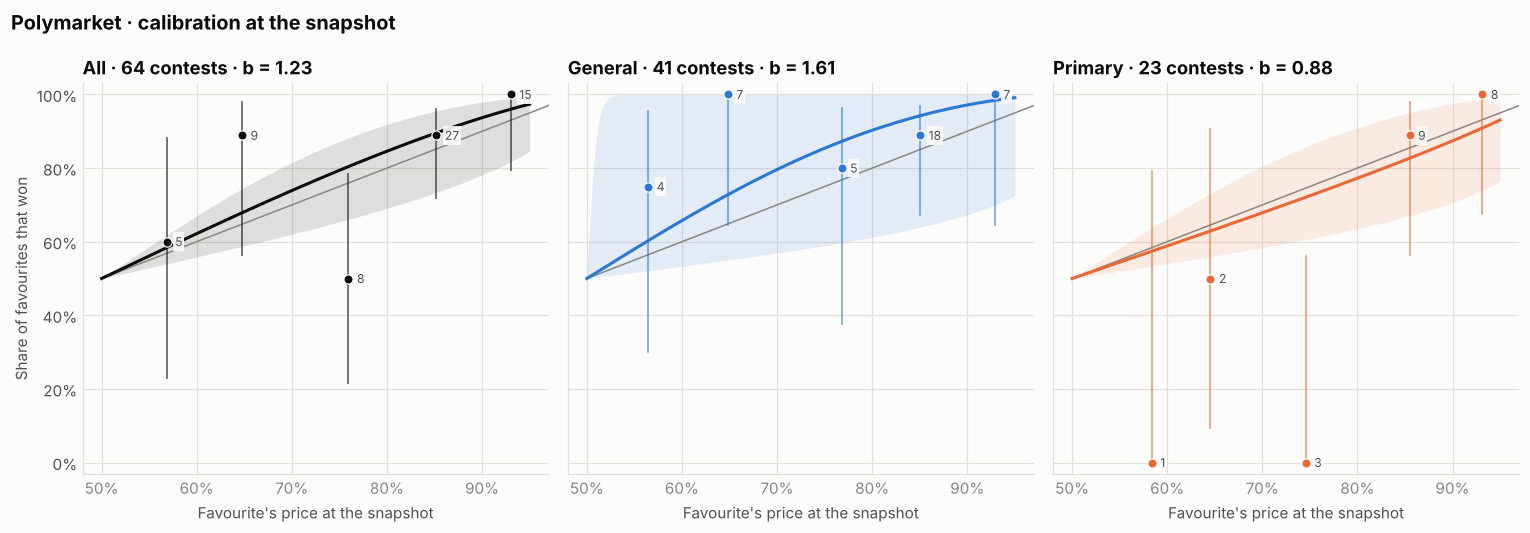

In [5]:
EDGES = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
grid = np.linspace(0.5, 0.95, 200)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.9), sharey=True)
for ax, (name, part) in zip(axes, GROUPS.items()):
    colour = COLOURS[name]
    curves = stretch.stretch(grid[None, :], np.clip(by_day[name].dropna().to_numpy()[:, None], -50, 50))
    low, high = np.nanquantile(curves, [0.025, 0.975], axis=0)
    ax.fill_between(grid, low, high, color=colour, alpha=0.12, linewidth=0)
    ax.plot([0.5, 1], [0.5, 1], color=MUTED, linewidth=1)
    ax.plot(grid, stretch.stretch(grid, estimate[name]), color=colour, linewidth=2)
    bins = pd.cut(part["price"], EDGES, include_lowest=True)
    for _, group in part.groupby(bins, observed=True):
        n, wins = len(group), group["won"].sum()
        low_, high_ = stretch.wilson(wins, n)
        x = group["price"].mean()
        ax.plot([x, x], [low_, high_], color=colour, linewidth=1.2, alpha=0.6)
        ax.scatter([x], [wins / n], s=36, color=colour, zorder=3, edgecolor=SURFACE, linewidth=0.8)
        ax.text(x + 0.009, wins / n, str(n), ha="left", va="center", fontsize=8, color=INK_2, zorder=4,
                bbox={"facecolor": SURFACE, "edgecolor": "none", "pad": 1.2, "alpha": 0.9})
    ax.set_xlim(0.48, 0.97)
    ax.set_ylim(-0.03, 1.03)
    percent(ax)
    ax.set_title(f"{name} · {len(part)} contests · b = {estimate[name]:.2f}", fontsize=12)
    ax.set_xlabel("Favourite's price at the snapshot")
    value_grid(ax, "both")
axes[0].set_ylabel("Share of favourites that won")
fig.suptitle(f"{PLATFORM} · calibration at the snapshot", x=0.01, ha="left", fontsize=13, weight="bold")
fig.tight_layout()
save(fig, "calibration")

## How sure we are about b

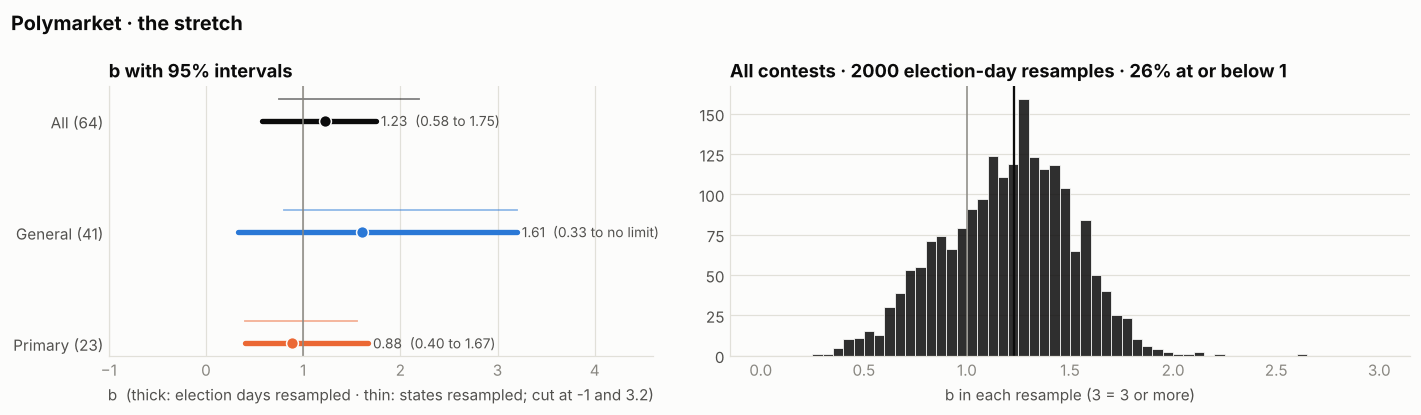

In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.25]})

names = list(GROUPS)[::-1]
for y, name in enumerate(names):
    row = fit_table.loc[name]
    clip = lambda v: float(np.clip(v, -1, 3.2))
    left.plot([clip(row["state_low"]), clip(row["state_high"])], [y + 0.2] * 2, color=COLOURS[name], linewidth=1.2, alpha=0.5)
    left.plot([clip(row["day_low"]), clip(row["day_high"])], [y] * 2, color=COLOURS[name], linewidth=3.5, solid_capstyle="round")
    left.scatter([row["b"]], [y], s=60, color=COLOURS[name], zorder=3, edgecolor=SURFACE, linewidth=1)
    left.text(clip(row["day_high"]) + 0.05, y, f"{row['b']:.2f}  ({span(row['day_low'], row['day_high'])})",
              va="center", fontsize=9, color=INK_2)
left.axvline(1, color=MUTED, linewidth=1)
left.set_yticks(range(len(names)), [f"{n} ({len(GROUPS[n])})" for n in names])
left.set_xlim(-1, 4.6)
left.set_xlabel("b  (thick: election days resampled · thin: states resampled; cut at -1 and 3.2)")
left.set_title("b with 95% intervals", fontsize=12)
value_grid(left, "x")

values = by_day["All"].replace([np.inf, -np.inf], np.nan).dropna()
right.hist(values.clip(upper=3), bins=np.arange(0, 3.05, 0.05), color=ALL, alpha=0.85, edgecolor=SURFACE, linewidth=0.6)
right.axvline(1, color=MUTED, linewidth=1)
right.axvline(estimate["All"], color=INK, linewidth=1.5)
right.set_title(f"All contests · {len(by_day)} election-day resamples · "
                f"{(by_day['All'] <= 1).mean():.0%} at or below 1", fontsize=12)
right.set_xlabel("b in each resample (3 = 3 or more)")
value_grid(right)
fig.suptitle(f"{PLATFORM} · the stretch", x=0.01, ha="left", fontsize=13, weight="bold")
fig.tight_layout()
save(fig, "stretch")

## Leave one election day out

For each election day, `b` is fitted on all the other days and used to score that day's contests. Lower log loss
(minus the log of the chance given to the actual winner) and lower Brier score are better. "Raw" is the scaled price
with no stretch.

In [7]:
held_out = stretch.leave_one_day_out(df)
held_out.to_csv(RESULTS / f"{SLUG}_leave_one_day_out.csv", index=False)
weights = held_out["contests"]
scores = pd.DataFrame({
    "raw price": [np.average(held_out["log_loss_raw"], weights=weights), np.average(held_out["brier_raw"], weights=weights)],
    "stretched": [np.average(held_out["log_loss_stretched"], weights=weights), np.average(held_out["brier_stretched"], weights=weights)],
}, index=["log loss", "Brier score"])
scores["stretch better by"] = scores["raw price"] - scores["stretched"]
scores.to_csv(RESULTS / f"{SLUG}_scores.csv")
print(f"The stretch lowered log loss on {(held_out['log_loss_gain'] > 0).sum()} of {len(held_out)} held-out days.")
scores.round(4)

The stretch lowered log loss on 16 of 23 held-out days.


,raw price,stretched,stretch better by
log loss,0.3885,0.4134,-0.0249
Brier score,0.1219,0.1294,-0.0076


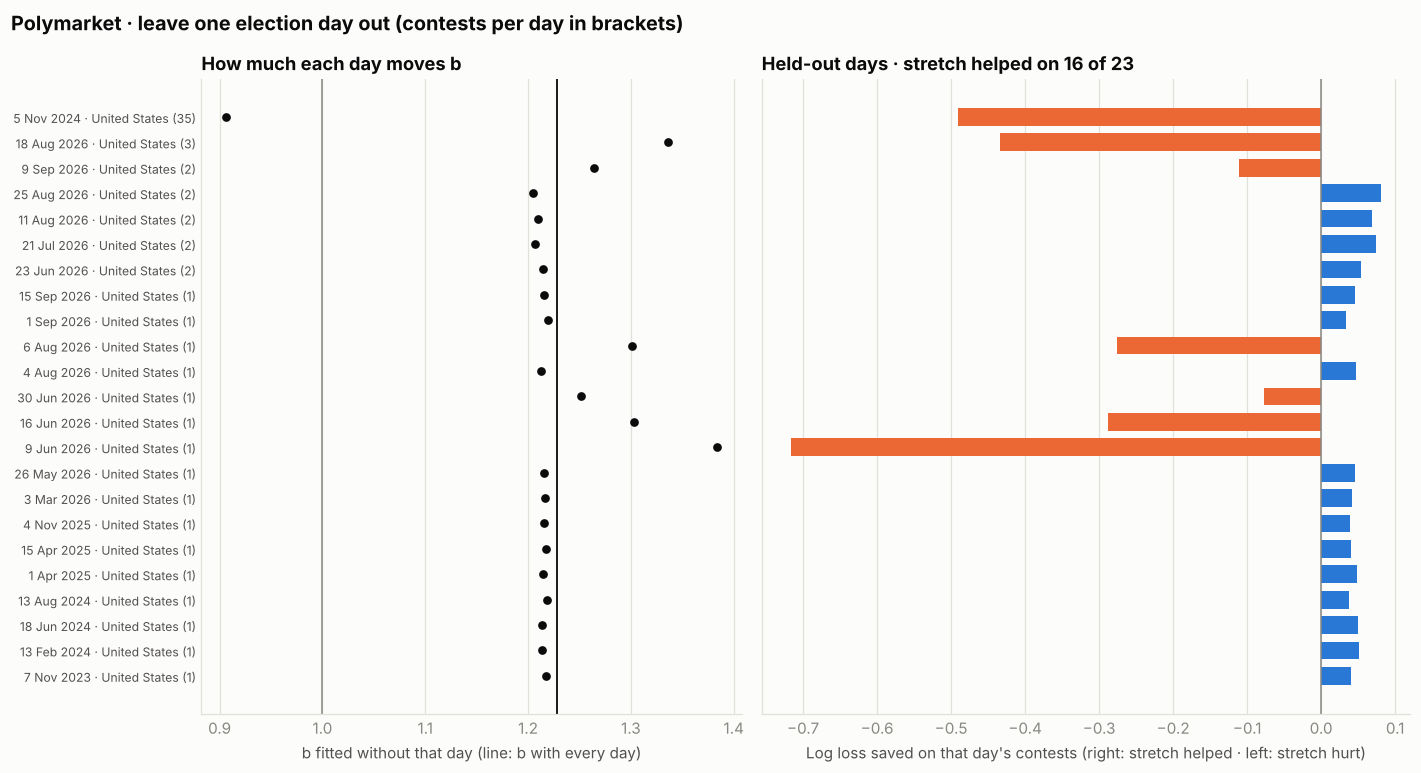

In [8]:
days = pd.read_csv("../calendar_and_prices/election_days.csv").set_index("key")
show = held_out.sort_values(["contests", "election_key"], ascending=[True, True]).reset_index(drop=True)
labels = [f"{pd.Timestamp(days.loc[k, 'last_voting_day']).strftime('%-d %b %Y')} · {days.loc[k, 'country']} ({n})"
          for k, n in zip(show["election_key"], show["contests"])]

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 0.24 * len(show) + 1.6), sharey=True,
                                  gridspec_kw={"width_ratios": [1, 1.2]})
y = np.arange(len(show))
left.axvline(estimate["All"], color=INK, linewidth=1.2)
left.axvline(1, color=MUTED, linewidth=1)
left.scatter(show["b_without_day"].clip(upper=3), y, s=22, color=ALL)
left.set_yticks(y, labels, fontsize=8)
left.set_xlabel("b fitted without that day (line: b with every day)")
left.set_title("How much each day moves b", fontsize=12)
value_grid(left, "x")

gain = show["log_loss_gain"] * show["contests"]  # total change in log loss on that day
right.barh(y, gain, color=np.where(gain > 0, GENERAL, PRIMARY), height=0.7)
right.axvline(0, color=MUTED, linewidth=1)
right.set_xlabel("Log loss saved on that day's contests (right: stretch helped · left: stretch hurt)")
right.set_title(f"Held-out days · stretch helped on {(show['log_loss_gain'] > 0).sum()} of {len(show)}", fontsize=12)
value_grid(right, "x")
fig.suptitle(f"{PLATFORM} · leave one election day out (contests per day in brackets)", x=0.01, ha="left",
             fontsize=13, weight="bold")
fig.tight_layout()
save(fig, "leave_one_day_out")

## All countries

The same fit on every kept contest, US or not, next to the US-only fit above (intervals resample election days).

In [9]:
everything = stretch.load(PLATFORM, us_only=False)
ALL_GROUPS = {"All": everything, "General": everything[everything["kind"] == "General"],
              "Primary": everything[everything["kind"] == "Primary"]}
everything_by_day = stretch.bootstrap(everything, "day", groups="kind")
rows = []
for name in GROUPS:
    part = ALL_GROUPS[name]
    low, high = stretch.interval(everything_by_day[name])
    us = fit_table.loc[name]
    rows.append({"group": name, "us_contests": int(us["contests"]), "us_b": us["b"], "us_low": us["day_low"],
                 "us_high": us["day_high"], "all_contests": len(part), "all_b": stretch.fit(part["log_odds"], part["won"]),
                 "all_low": low, "all_high": high})
comparison = pd.DataFrame(rows).set_index("group")
comparison["difference"] = comparison["all_b"] - comparison["us_b"]
comparison.to_csv(RESULTS / f"{SLUG}_us_vs_all.csv")
print(f"{len(everything) - len(df)} contests outside the US are added here.")
comparison.round(3)

20 contests outside the US are added here.


,us_contests,us_b,us_low,us_high,all_contests,all_b,all_low,all_high,difference
group,,,,,,,,,
All,64,1.228,0.58,1.750,84,1.051,0.550,1.539,-0.178
General,41,1.608,0.33,inf,61,1.151,0.358,1.847,-0.457
Primary,23,0.882,0.40,1.669,23,0.882,0.404,1.636,0.000


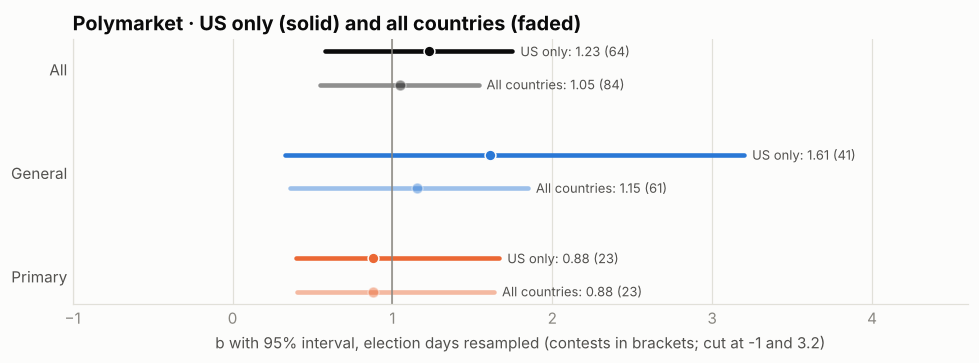

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.4))
clip = lambda v: float(np.clip(v, -1, 3.2))
names = list(GROUPS)[::-1]
for y, name in enumerate(names):
    row = comparison.loc[name]
    for offset, prefix, alpha, label in ((0.16, "us", 1.0, "US only"), (-0.16, "all", 0.45, "All countries")):
        ax.plot([clip(row[f"{prefix}_low"]), clip(row[f"{prefix}_high"])], [y + offset] * 2, color=COLOURS[name],
                linewidth=3, alpha=alpha, solid_capstyle="round")
        ax.scatter([row[f"{prefix}_b"]], [y + offset], s=50, color=COLOURS[name], alpha=alpha, zorder=3,
                   edgecolor=SURFACE, linewidth=1)
        ax.text(clip(row[f"{prefix}_high"]) + 0.05, y + offset,
                f"{label}: {row[f'{prefix}_b']:.2f} ({int(row[f'{prefix}_contests'])})", va="center", fontsize=8.5,
                color=INK_2)
ax.axvline(1, color=MUTED, linewidth=1)
ax.set_yticks(range(len(names)), names)
ax.set_xlim(-1, 4.6)
ax.set_xlabel("b with 95% interval, election days resampled (contests in brackets; cut at -1 and 3.2)")
ax.set_title(f"{PLATFORM} · US only (solid) and all countries (faded)")
value_grid(ax, "x")
fig.tight_layout()
save(fig, "us_vs_all")